In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
X = panel[FEATURES].fillna(panel[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

In [3]:
panel["cluster"] = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(X_scaled)
print(panel["cluster"].value_counts().sort_index())
print(f"noise: {(panel['cluster'] == -1).mean():.1%}")

cluster
-1     625
 0      35
 1      46
 2      31
 3     270
 4      20
 5     132
 6      22
 7      26
 8      49
 9      19
 10     57
 11     15
 12     44
 13     29
 14     65
 15     55
 16     36
 17     53
 18     21
 19     47
 20     16
 21     39
 22     39
 23     47
 24     40
 25     52
 26     57
 27     36
 28     47
Name: count, dtype: int64
noise: 30.2%


HDBSCAN groups days together based on how similar they are across 11 scaled features (LTV, loop depth, distance to liquidation, volatility, rebalancing frequency, and carry spread). Each day gets a cluster label, or -1 if it is "noise" and does not fit any dense group well.

On the full 24-whale panel (2,070 days), this untuned run finds about 29 small clusters, with 30% of days labeled as noise.

Two settings control how clusters form: a cluster needs at least 15 similar days to count (min_cluster_size=15), and each day is judged by looking at its 5 nearest neighbors (min_samples=5).

### PCA plot coloured by cluster

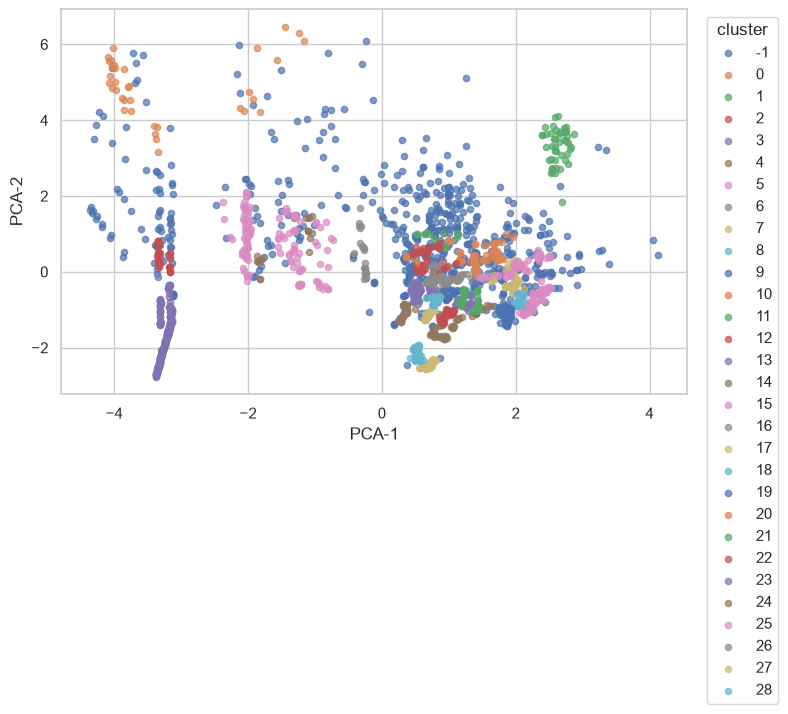

In [4]:
pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
for c in sorted(panel["cluster"].unique()):
    s = panel[panel["cluster"] == c]
    ax.scatter(s["x"], s["y"], label=c, alpha=0.7, s=20)
ax.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

This chart plots every day in 2D space using PCA, and colors each point by its HDBSCAN cluster. Points close together behave similarly across the 11 features. The gray dots are noise (cluster -1).

A few patterns stand out:
- The gray noise points (about 30% of days) are scattered across the middle and edges, sitting between the dense groups.
- A group on the far left has low leverage and high distance to liquidation. These days are clearly separate from the active looping whales.
- Groups near the top and right have very high LTV, loop depth, and carry spread. These are max leverage days, far from the main cloud of points.
- Several high leverage groups are split by how recently they rebalanced, with little overlap between fresh and stale groups.
- A group near the bottom has high LTV but negative carry spread. These are days where the carry trade is underwater.
- The center right holds the largest block of active looping days (LTV around 90%, moderate loop depth), with a nearby group that rebalances more often.

The main problem here is fragmentation. About 29 tiny clusters is too many to count as clean archetypes, and several of them are really just one whale on its own (W-11 stands out here). This is why we move to a balanced fit in notebook 03.

### PCA plot coloured by `whale_id`

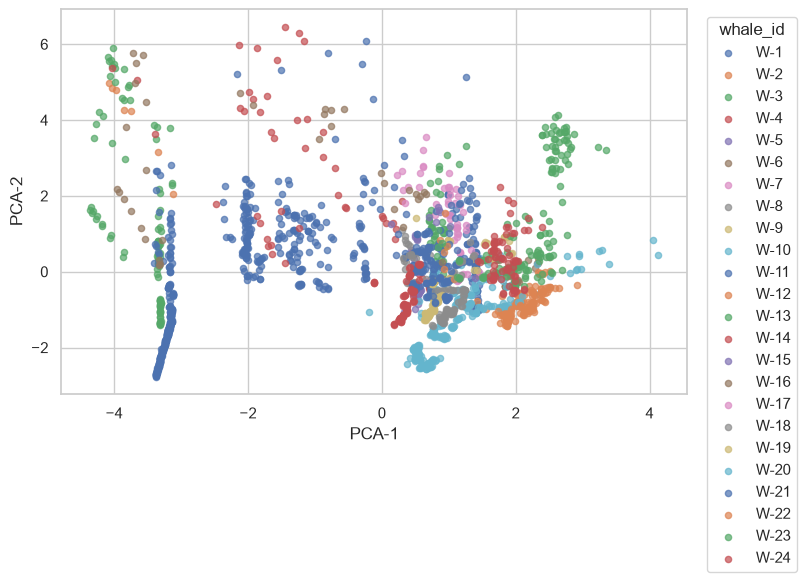

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for w in sorted(panel["whale_id"].unique(), key=lambda w: int(w.split("-")[1])):
    s = panel[panel["whale_id"] == w]
    ax.scatter(s["x"], s["y"], label=w, alpha=0.7, s=20)
ax.legend(title="whale_id", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

This chart shows the same PCA space as before, but now colored by whale instead of cluster. This makes it easy to see how each whale spreads across leverage, rebalancing, and carry.

The panel now covers all 24 whales (W-1 to W-17 are Morpho, W-18 to W-24 are Aave). W-17 only has 1 day that can be clustered.

W-3 is still the most versatile whale and covers the widest area of the chart. W-11 has 622 active days, more than any other whale, so it has a big effect on the untuned fit. W-10 and W-13 add long stretches of high LTV days. The Aave whales (W-18 to W-24) sit in the high LTV region, close to the more aggressive Morpho whales.

Most other whales sit in tighter, smaller patches. This shows that the baseline clustering often groups days by which whale made them, rather than by a shared strategy. This is why notebook 03 balances the data per whale before fitting.

In [6]:
panel.groupby("cluster")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster,,,,,,,,,,,
-1,0.700,7.333,0.219,0.019,0.050,1.840,5.616,8.275,0.692,8.186,49.538
0,0.166,0.771,0.799,0.399,0.352,2.314,5.914,1.514,0.889,3.292,2.313
1,0.958,24.043,0.007,0.000,0.001,5.109,18.565,0.435,0.959,3.691,88.769
2,0.000,0.000,0.931,0.000,0.000,1.452,9.065,2.839,0.000,3.359,0.000
3,0.000,0.000,0.872,0.000,0.000,0.000,0.822,71.411,0.000,4.918,0.000
4,0.327,1.550,0.533,0.002,0.002,1.650,8.300,2.850,0.329,24.370,38.507
5,0.332,1.485,0.528,0.009,0.020,1.803,8.167,3.106,0.355,9.623,14.234
6,0.650,3.000,0.210,0.003,0.015,0.773,8.955,7.364,0.658,3.655,10.966
7,0.825,6.000,0.090,0.001,0.001,0.000,0.000,195.423,0.826,10.313,61.875


Untuned HDBSCAN still finds risk states that make sense (things like flat low leverage, max loop, stale positions, negative carry, and active rebalancing) but it has some problems:

- There are far too many clusters (about 29 plus noise) to count as clean archetypes across 2,070 days.
- A large share of days (about 30%) land in cluster -1, meaning they are treated as noise.
- Several of the small clusters are really just one whale on its own (W-11 in particular).

Notebook 03_balanced_clustering.ipynb fixes this. It balances the data across whales, tunes min_cluster_size, and builds 3 to 4 clear archetypes that work across all whales.